# Ball on flat: SlipPY static BEM against Hertz, grid convergence and resolution

**Case:** `validation/contact/hertz_point_grid_domain` (V-DRY-01, V-DRY-04), criteria P1-P3 of
the README.

A 12.7 mm steel ball pressed on a steel flat (circular point contact) is solved with SlipPY's
static BEM through `slippy_bridge.contact` on a series of grids (`validation._support.convergence.sweep`,
mesh sweep at half-length $4a$). The judge is `references.contact.hertz.hertz_point` (Johnson
1985, Eqs (4.22)-(4.24)); the bridge record's `err_*` (against SlipPY's own `hertz_full`) are kept
in the CSV as information and never graded.

- **P1** default grid: $a$, $p_0$, $\delta$, $p_m$ against the closed forms. The measured radius
  is $\sqrt{s_x s_y}$, from the semi-axes that `slippy_bridge.contact.measure` places below one node.
- **P2** mesh sweep, Polonsky & Keer's own measures: $\varepsilon_r = |\sqrt{A/\pi} - a|/a$ with
  $A = N_c h^2$ ($N_c$ loaded nodes), and $\varepsilon_p = \sum_{I_c}|p_{ij} - p_H(x_i, y_j)| /
  \sum_{I_c} p_H(x_i, y_j)$ over the loaded nodes $I_c$; limits $\varepsilon_r < 1/M$,
  $\varepsilon_p \le M^{-3/2}$, $M = 2a/h$ nodes across the contact diameter.
- **P3** Muser's rule: $h = a/32$ in a cell of side $8a$ gives a contact area within 0.1 %.

`--smoke`: the coarsest grid ($2h_0$) and the composite build only; P3 not run.

In [1]:
import math
import sys

import numpy as np
import matplotlib.pyplot as plt
from axisforge.outputs._format import format_table, write_records_csv

from references.contact.hertz import hertz_point
from slippy_bridge.contact import Grid, pair, static_step
from validation._support.convergence import RECORD_COLUMNS, sweep
from validation._support.figures import contact_plots
from validation._support.style import use_style

from construction import CASE, H_LEVELS, MUSER_H_OVER_A, MUSER_SPAN, RESULTS, SPAN_X_0

use_style()                                       # house paper style (style/README.md)
SMOKE = "--smoke" in sys.argv                     # step-7 smoke run; a notebook runs the full grids
NAME = "01_ball_flat"
RESULTS.mkdir(exist_ok=True)                      # git-ignored (D-0020)
BUILDS = ("composite",) if SMOKE else ("composite", "two_profiles")
H_RUN = (2.0,) if SMOKE else H_LEVELS             # grid spacings in units of h0 [-]

JUDGE = hertz_point(CASE.r1, CASE.r2, CASE.E, CASE.nu, CASE.load)
A = JUDGE["s_x_m"]                                # circular contact: s_x = s_y = a [m]
P_M = CASE.load / (math.pi * A**2)                # mean pressure P/(pi a^2) [Pa]; p0 = (3/2) p_m
h0 = Grid.around(CASE).h                          # default spacing of the bridge [m]

## 1. Mesh sweep

Each record of `sweep` gets the measured radius and its error, $p_0$, $\delta$ and $p_m$ errors
against the judge, and $M$.

In [2]:
def judged(record):
    """The record with the errors against the judge (fractions) and M = 2a/h."""
    a_meas = math.sqrt(record["s_x_m"] * record["s_y_m"])            # radius of the measured area [m]
    return {**record, "a_m": a_meas, "M": 2.0 * A / record["h_m"],
            "eps_a": (a_meas - A) / A, "eps_p0": (record["p0_Pa"] - JUDGE["p0_Pa"]) / JUDGE["p0_Pa"],
            "eps_delta": (record["delta_m"] - JUDGE["delta_m"]) / JUDGE["delta_m"],
            "eps_p_m": (record["load_N"] / (math.pi * a_meas**2) - P_M) / P_M}


records = [judged(r) for r in sweep(CASE, BUILDS, H_RUN, (), RESULTS / "slippy_01", span_x_0=SPAN_X_0)]

JUDGED_COLUMNS = (("build", "build", "s"), ("h_m", "h [um]", ".3f", 1e6), ("M", "M", ".1f"),
                  ("eps_a", "eps a [%]", "+.3f", 100.0), ("eps_p0", "eps p0 [%]", "+.3f", 100.0),
                  ("eps_delta", "eps delta [%]", "+.3f", 100.0), ("eps_p_m", "eps p_m [%]", "+.3f", 100.0))
print(f"{CASE.label}   case_hash {CASE.case_hash()}   judge: a {A * 1e3:.5f} mm, "
      f"p0 {JUDGE['p0_Pa'] * 1e-6:.2f} MPa, delta {JUDGE['delta_m'] * 1e6:.4f} um")
print(format_table(RECORD_COLUMNS, records))
print()
print(format_table(JUDGED_COLUMNS, records))

ball_flat   case_hash 9ccc2ddabd085997   judge: a 0.27430 mm, p0 3173.02 MPa, delta 11.8485 um
       build  sweep  span_x [s_x]  h [um]  n_x  n_y  p0 [MPa]  err p0 [%]  err s_x [%]  err s_y [%]  err delta [%]  t [s]
------------  -----  ------------  ------  ---  ---  --------  ----------  -----------  -----------  -------------  -----
   composite   mesh             4  30.518   74   26   3184.23      +0.353       +0.633       +0.325         +1.074   0.52
   composite   mesh             4  15.259  146   50   3181.65      +0.272       +0.422       +0.137         +1.260   0.92
   composite   mesh             4   7.629  290   96   3182.91      +0.312       +0.352       -0.811         +1.535   1.42
   composite   mesh             4   3.815  578  190   3183.23      +0.322       +0.335       -0.974         +1.600   7.17
two_profiles   mesh             4  30.518   74   26   3184.23      +0.353       +0.633       +0.325         +1.074   0.13
two_profiles   mesh             4  15.259  146   50

## 2. P2: Polonsky & Keer's error measures on the pressure field

`sweep` returns records, not pressure fields, and P&K's measures need the field: the mesh levels
are solved again here (composite build), repeating the few lines of `sweep`'s loop on purpose.
The Hertz pressure $p_H = p_0\sqrt{1 - (r/a)^2}$ uses the judge's $p_0$ and $a$.

In [3]:
pk = []
for i, f in enumerate(H_RUN):
    grid = Grid.around(CASE, h=f * h0, span_x=SPAN_X_0)
    record, p = static_step.run(CASE, pair(CASE, grid), grid, RESULTS / "slippy_01", name=f"{CASE.label}_pk_{i}")
    p_h = JUDGE["p0_Pa"] * np.sqrt(np.clip(1.0 - (grid.X**2 + grid.Y**2) / A**2, 0.0, None))
    loaded = p > 0.0                                                # I_c: the loaded nodes of the solution
    area = loaded.sum() * grid.h**2                                 # A = N_c h^2 [m^2]
    pk.append({"h_m": grid.h, "M": 2.0 * A / grid.h, "N_c": int(loaded.sum()),
               "eps_r": abs(math.sqrt(area / math.pi) - A) / A,
               "eps_p": float(np.abs(p - p_h)[loaded].sum() / p_h[loaded].sum())})
    if f == (H_RUN[0] if SMOKE else 1.0):
        p_default, grid_default = p, grid                           # the default grid (smoke: 2 h0), for the figure

print(format_table((("h_m", "h [um]", ".3f", 1e6), ("M", "M", ".1f"), ("N_c", "N_c", ".0f"),
                    ("eps_r", "eps_r [%]", ".4f", 100.0), ("eps_p", "eps_p [%]", ".4f", 100.0)), pk))

h [um]      M    N_c  eps_r [%]  eps_p [%]
------  -----  -----  ---------  ---------
30.518   18.0    261     1.4090     1.1093
15.259   36.0   1025     0.4819     0.8601
 7.629   71.9   4075     0.1751     0.8925
 3.815  143.8  16255     0.0368     0.9011


## 3. P3: Muser's resolution

One solve, composite build: spacing $a/32$ (rounded down to $2^k$ m by `Grid.around`) and
half-length $4a$ on both axes ($a_c/L = 1/8$). Muser's 0.1 % holds for an area from a fit of the
radial pressure profile; here it is the area $\pi s_x s_y$ of the measured semi-axes, whose
edges `slippy_bridge.contact.measure` places below one node.

In [4]:
muser = None
if not SMOKE:
    grid = Grid.around(CASE, h=MUSER_H_OVER_A * A, span_x=MUSER_SPAN, span_y=MUSER_SPAN)
    record, _ = static_step.run(CASE, pair(CASE, grid), grid, RESULTS / "slippy_01", name=f"{CASE.label}_muser")
    muser = judged({"build": "composite", "sweep": "muser", "span_x": MUSER_SPAN,
                    "use_frequency_domain": True, **record})

## 4. Criteria

P1 on the default grid $h_0$ (smoke: $2h_0$, the only one). P2's observed order is the slope of
$\log\varepsilon_p$ against $\log h$ between the two finest grids (**[proposed]** reading of
"on the order of $M^{-3/2}$").

In [5]:
def row(cid, quantity, build, value, expected, err, limit, ok):
    """One criteria record; ``ok`` None means recorded only."""
    return {"id": cid, "quantity": quantity, "build": build, "value": value, "expected": expected,
            "err": err, "limit": limit, "result": "recorded" if ok is None else ("PASS" if ok else "FAIL")}


criteria = []
for build in BUILDS:
    mesh = [r for r in records if r["build"] == build]
    default = [r for r in mesh if r["h_m"] == h0]
    if not default and not SMOKE:
        raise RuntimeError(f"no record on the default grid h0 = {h0} m for build {build}")
    d = default[0] if default else mesh[0]                          # smoke: the only grid, 2 h0
    M = d["M"]
    criteria += [
        row("P1", "a [m] [proposed]", build, d["a_m"], A, d["eps_a"], f"< 1/M = {1 / M:.4f}",
            abs(d["eps_a"]) < 1 / M),
        row("P1", "p0 [Pa] [proposed]", build, d["p0_Pa"], JUDGE["p0_Pa"], d["eps_p0"],
            f"<= M^-1.5 = {M**-1.5:.5f}", abs(d["eps_p0"]) <= M**-1.5),
        row("P1", "delta [m] [proposed]", build, d["delta_m"], JUDGE["delta_m"], d["eps_delta"], "<= 0.02",
            abs(d["eps_delta"]) <= 0.02),
        row("P1", "p_m [Pa]", build, d["load_N"] / (math.pi * d["a_m"] ** 2), P_M, d["eps_p_m"], "-", None),
    ]
for r in pk:
    criteria += [
        row("P2", f"eps_r (N_c h^2) at M = {r['M']:.1f}", "composite", r["eps_r"], 0.0, r["eps_r"],
            f"< {1 / r['M']:.4f}", r["eps_r"] < 1 / r["M"]),
        row("P2", f"eps_p (L1, contact nodes) at M = {r['M']:.1f}", "composite", r["eps_p"], 0.0, r["eps_p"],
            f"<= {r['M'] ** -1.5:.5f}", r["eps_p"] <= r["M"] ** -1.5),
    ]
if len(pk) >= 2:
    f1, f2 = sorted(pk, key=lambda r: r["h_m"])[:2]                 # the two finest grids
    order = math.log(f2["eps_p"] / f1["eps_p"]) / math.log(f2["h_m"] / f1["h_m"])
    criteria.append(row("P2", "observed order of eps_p [proposed]", "composite", order, 1.5, math.nan, ">= 1.5",
                        order >= 1.5))
else:
    criteria.append(row("P2", "observed order of eps_p [proposed] (one grid)", "composite", math.nan, 1.5,
                        math.nan, ">= 1.5", None))
if muser is None:
    criteria.append(row("P3", "area at h = a/32, L = 8a (not run: smoke)", "composite", math.nan, math.pi * A**2,
                        math.nan, "< 0.001", None))
else:
    area = math.pi * muser["s_x_m"] * muser["s_y_m"]
    err = area / (math.pi * A**2) - 1.0
    criteria.append(row("P3", f"area at h = a/{A / muser['h_m']:.1f}, L = 8a [m^2]", "composite", area,
                        math.pi * A**2, err, "< 0.001", abs(err) < 0.001))

CRITERIA_COLUMNS = (("id", "ID", "s"), ("quantity", "quantity", "s"), ("build", "build", "s"),
                    ("value", "value", ".6g"), ("expected", "expected", ".6g"), ("err", "err [%]", "+.4f", 100.0),
                    ("limit", "limit", "s"), ("result", "result", "s"))
print(format_table(CRITERIA_COLUMNS, criteria))
write_records_csv(RESULTS / f"{NAME}.csv", records + ([muser] if muser else []))
write_records_csv(RESULTS / f"{NAME}_pk.csv", pk)
write_records_csv(RESULTS / f"{NAME}_criteria.csv", criteria)

ID                                quantity         build        value     expected  err [%]                limit    result
--  --------------------------------------  ------------  -----------  -----------  -------  -------------------  --------
P1                        a [m] [proposed]     composite  0.000275063  0.000274296  +0.2797       < 1/M = 0.0278      PASS
P1                      p0 [Pa] [proposed]     composite  3.18165e+09  3.17302e+09  +0.2718  <= M^-1.5 = 0.00464      PASS
P1                    delta [m] [proposed]     composite  1.19978e-05  1.18485e-05  +1.2601              <= 0.02      PASS
P1                                p_m [Pa]     composite  2.10357e+09  2.11535e+09  -0.5570                    -  recorded
P1                        a [m] [proposed]  two_profiles  0.000275063  0.000274296  +0.2797       < 1/M = 0.0278      PASS
P1                      p0 [Pa] [proposed]  two_profiles  3.18165e+09  3.17302e+09  +0.2718  <= M^-1.5 = 0.00464      PASS
P1              

## 5. Figures

Convergence of the bridge errors (information: they are against SlipPY's `hertz_full`) and the
pressure through the centre on the default grid against the Hertz pressure.

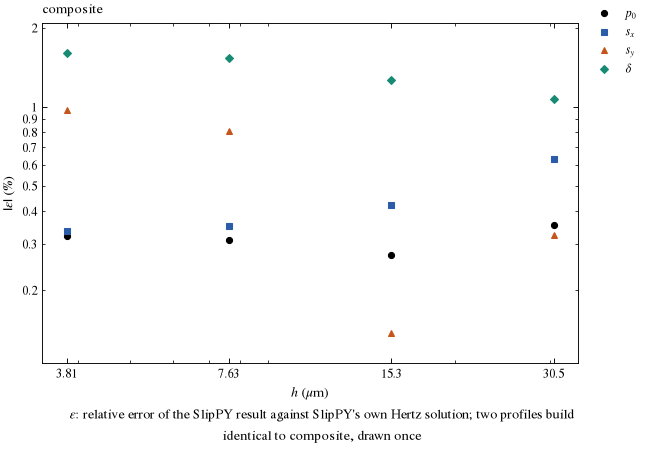

In [6]:
fig = contact_plots.convergence(records, RESULTS / f"{NAME}_convergence.png")
plt.close(fig)                                    # shown once, by the line below
fig

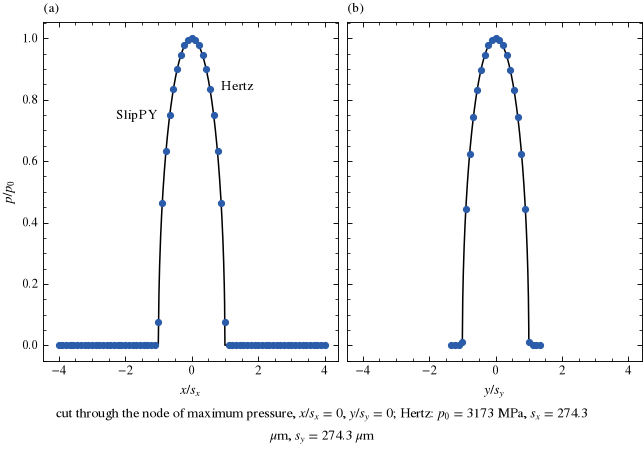

In [7]:
fig = contact_plots.pressure_cuts(p_default, grid_default, JUDGE, RESULTS / f"{NAME}_pressure_cuts.png")
plt.close(fig)                                    # shown once, by the line below
fig